
## Импорт библиотек и загрузка данных

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
DATASET = "https://raw.githubusercontent.com/Anastasiien/credit_risk/refs/heads/main/credit_risk_dataset.csv"

In [ ]:
df = pd.read_csv(DATASET)

In [ ]:
df.head(10)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2
6,26,77100,RENT,8.0,EDUCATION,B,35000,12.42,1,0.45,N,3
7,24,78956,RENT,5.0,MEDICAL,B,35000,11.11,1,0.44,N,4
8,24,83000,RENT,8.0,PERSONAL,A,35000,8.90,1,0.42,N,2
9,21,10000,OWN,6.0,VENTURE,D,1600,14.74,1,0.16,N,3


## Описание данных

person_age - возраст

person_income	- годовой доход

person_home_ownership - владение домом (RENT - аренда, OWN - владение, MORTGAGE - ипотека, OTHER - иное)

person_emp_length	- продолжительность трудовой деятельности (в годах)

loan_intent - цель займа (DEBTCONSOLIDATION - консолидация долга, EDUCATION - образование, HOMEIMPROVEMENT - ремонт дома, MEDICAL - медецина, PERSONAL	- на личные нужды,  VENTURE - предприятие)

loan_grade - кредитный рейтинг от A до G (A — самый хороший рейтинг, G — самый плохой)

loan_amnt - сумма кредита

loan_int_rate	- процентная ставка

loan_status - статус кредита (0 - исполнение обязательств, 1 - не исполнение обязательств). - целевая переменная

loan_percent_income - процентный доход (чем меньше значение, тем вероятнее возврат кредита)

cb_person_default_on_file	- исторический дефолт

cb_person_cred_hist_length - продолжительность кредитной истории

посмотрим какие есть типы в датасете

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


узнаем, есть ли пустые ячейки в колонках

In [ ]:
df.isnull().mean() * 100

,0
person_age,0.000000
person_income,0.000000
person_home_ownership,0.000000
person_emp_length,2.747000
loan_intent,0.000000
loan_grade,0.000000
loan_amnt,0.000000
loan_int_rate,9.563856
loan_status,0.000000
loan_percent_income,0.000000


пустые ячейки есть, посмотрим сколько в каждой

In [ ]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


loan_int_rate - достаточно много, надо узнать сколько всего строк в датасете

In [ ]:
df.shape

(32581, 12)

Около 10% пропусков в одной колонке, для обычного удаления это слишком много, лучше заполнить средним значением, но брать среднее от всех возможных процентов, скорее всего, будет неверно так как он может зависеть от других признаков. Проверим не зависит ли процент по кредиту от кредитного рейтинга

In [ ]:
groups = df.groupby('loan_grade')['loan_int_rate'].mean() # берем среднее значение по loan_int_rate в зависимости какой loan_grade
print(groups)

loan_grade
A     7.327651
B    10.995555
C    13.463542
D    15.361448
E    17.009455
F    18.609159
G    20.251525
Name: loan_int_rate, dtype: float64


Зависит, чем хуже рейтинг, тем выше процент по кредиту. Подставим среднее значение процента в зависимости от рейтинга клиента

In [ ]:
df['loan_int_rate'] = df.groupby('loan_grade')['loan_int_rate'].transform(lambda x: x.fillna(x.mean()))

In [ ]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,0
loan_status,0
loan_percent_income,0


Теперь пропусков в столбце loan_int_rate нет

Осталось что-то сделать с person_emp_length, он зависит он возраста клиентов, проверим нет ли выбросов (ошибочных значений) в возрасте

In [ ]:
df['person_age'].describe()

,person_age
count,32581.000000
mean,27.734600
std,6.348078
min,20.000000
25%,23.000000
50%,26.000000
75%,30.000000
max,144.000000


минимальный возраст 20 лет, максимальный 144, слишком большой. Возьмем только тех кому меньше 95

In [ ]:
(df['person_age'] >= 95).sum()

np.int64(5)

количество убраных ошибочных значений - 5

In [ ]:
df = df[df['person_age'] < 95]

In [ ]:
df.shape

(32576, 12)

было - 32581 , стало - 32576. все верно

In [ ]:
pd.cut(df['person_age'], bins=[19, 35, 60, 95]) # функция присваевает каждому возрасту свой интервал по bins, всего 3 интервала, так как минимальный возраст 20, а берется левая сторона не включительно, поэтому минимальный возраст поставим 19

,person_age
0,"(19, 35]"
1,"(19, 35]"
2,"(19, 35]"
3,"(19, 35]"
4,"(19, 35]"
...,...
32576,"(35, 60]"
32577,"(35, 60]"
32578,"(60, 95]"
32579,"(35, 60]"


In [ ]:
df['person_emp_length'] = df.groupby(pd.cut(df['person_age'], bins=[19, 35, 60, 95]))['person_emp_length'].transform(lambda x: x.fillna(x.mean()))

/tmp/ipykernel_3137/2541923457.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df['person_emp_length'] = df.groupby(pd.cut(df['person_age'], bins=[19, 35, 60, 95]))['person_emp_length'].transform(lambda x: x.fillna(x.mean()))


In [ ]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,0
loan_status,0
loan_percent_income,0


теперь пропусков нет

проверим выбросы по каждому признаку

<Axes: ylabel='person_age'>

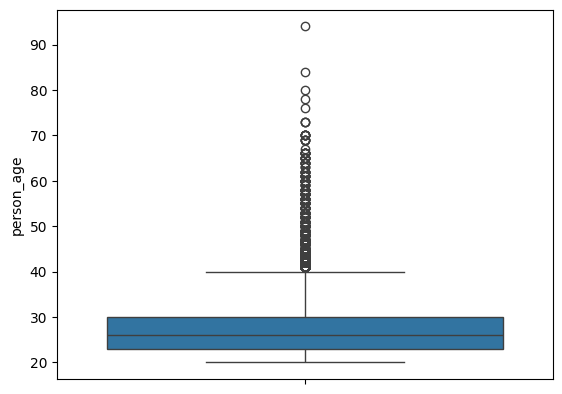

In [ ]:
sns.boxplot(data = df.person_age)

график показывает выбросы которых много, но в целом это реально возможный возраст и такие люди могут брать кредиты

<Axes: ylabel='person_income'>

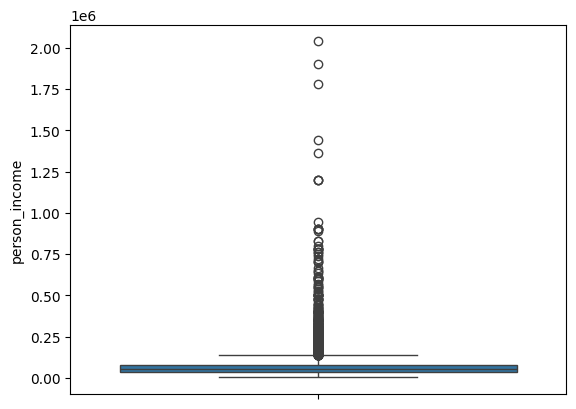

In [ ]:
sns.boxplot(data = df.person_income)

В целом это годовой доход и люди с состоянием тоже могут брать кредиты, такие реальные данные могут наоборот лучше научить модель, если такого не будет, она может выдовать ошибочные данные при работе, поэтому специфичные кейсы удалять не будем, это не точная ошибка

<Axes: xlabel='person_home_ownership', ylabel='count'>

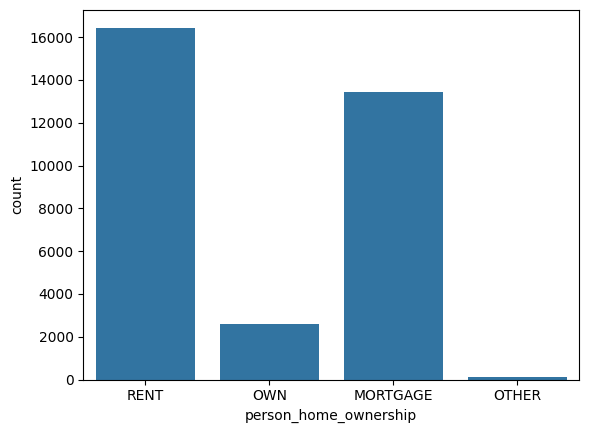

In [ ]:
sns.countplot(data = df, x = 'person_home_ownership')

Так как признак категориальный, то использую countplot, тут опечаток нет, менять ничего не надо

<Axes: ylabel='person_emp_length'>

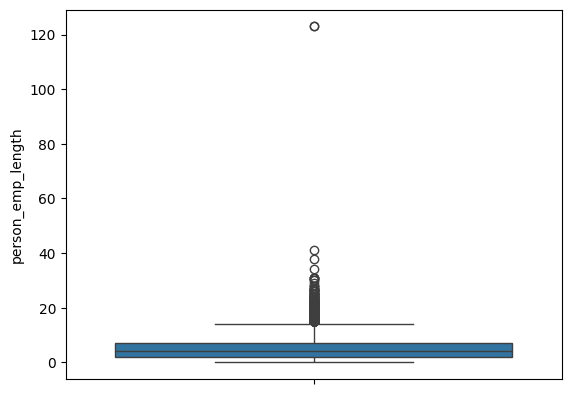

In [ ]:
sns.boxplot(data = df.person_emp_length)

In [ ]:
df['person_emp_length'].describe()

,person_emp_length
count,32576.000000
mean,4.789216
std,4.085946
min,0.000000
25%,2.000000
50%,4.000000
75%,7.000000
max,123.000000


Есть выброс, у человека стаж больше 120 лет, точно ошибка. Так как были оставлены люди, которым меньше 95, а минимальный возраст с которого можно работать - 14, то 81 год максимального стажа, получается удаляем одного человека - 123 года стажа

In [ ]:
df = df[df['person_emp_length'] < 81]

<Axes: ylabel='person_emp_length'>

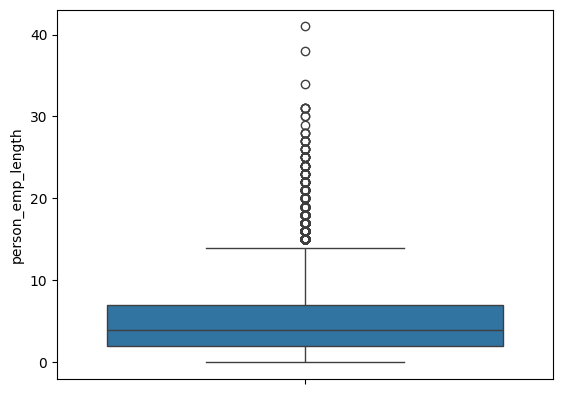

In [ ]:
sns.boxplot(data = df.person_emp_length)

выброса нет, стаж немного больше 40 лет - нормально, не выброс

<Axes: xlabel='loan_intent', ylabel='count'>

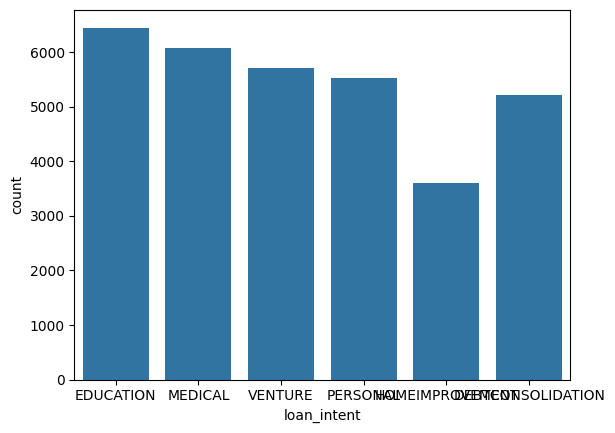

In [ ]:
sns.countplot(data = df, x = 'loan_intent')

ошибочных значений нет

<Axes: xlabel='loan_grade', ylabel='count'>

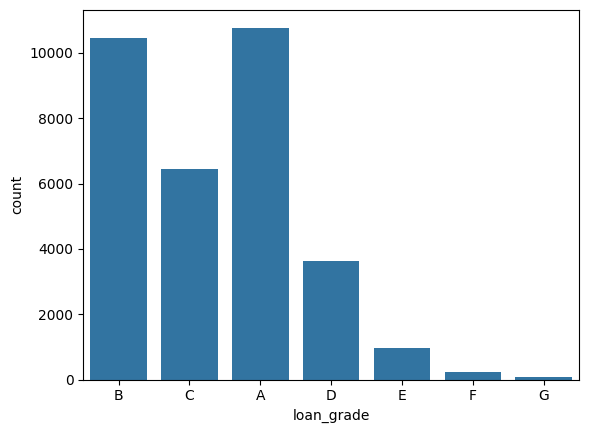

In [ ]:
sns.countplot(data = df, x = 'loan_grade')

ошиочных значений нет

<Axes: ylabel='loan_amnt'>

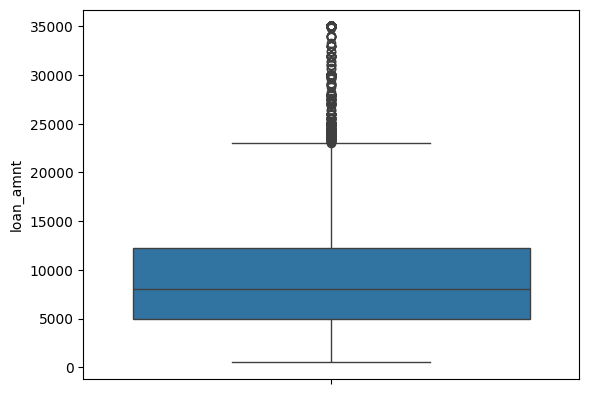

In [ ]:
sns.boxplot(data = df.loan_amnt)

выбросов нет

<Axes: ylabel='loan_int_rate'>

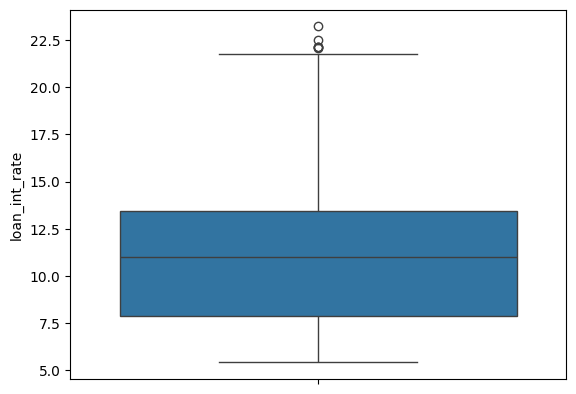

In [ ]:
sns.boxplot(data = df.loan_int_rate)

выбросов нет

<Axes: ylabel='loan_status'>

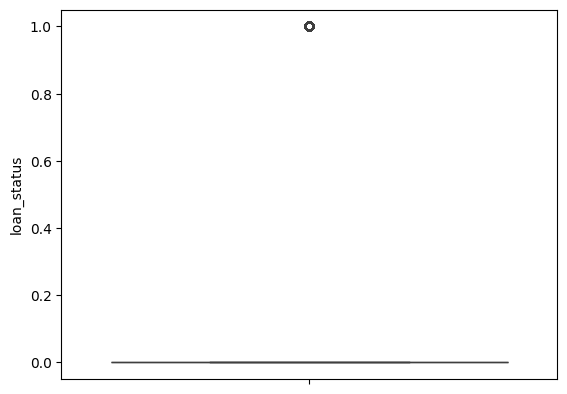

In [ ]:
sns.boxplot(data = df.loan_status)

значения только 0 и 1, ошибок нет

<Axes: ylabel='loan_percent_income'>

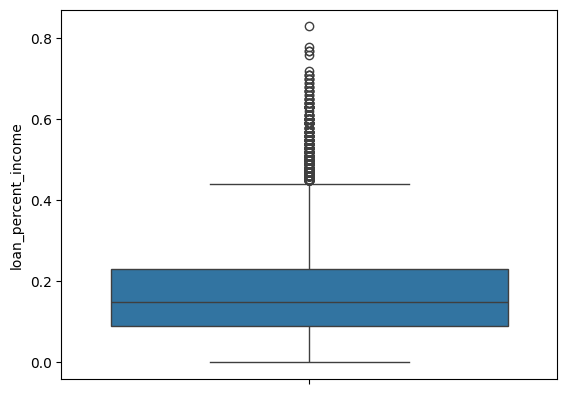

In [ ]:
sns.boxplot(data = df.loan_percent_income)

In [ ]:
df['loan_percent_income'].describe()

,loan_percent_income
count,32574.000000
mean,0.170202
std,0.106755
min,0.000000
25%,0.090000
50%,0.150000
75%,0.230000
max,0.830000


максимум не достигает 1, ошибок нет

<Axes: xlabel='cb_person_default_on_file', ylabel='count'>

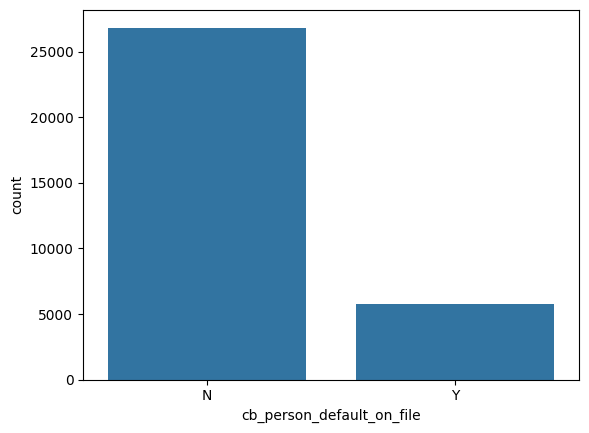

In [ ]:
sns.countplot(data = df, x = 'cb_person_default_on_file')

ошибочных значений нет

<Axes: ylabel='cb_person_cred_hist_length'>

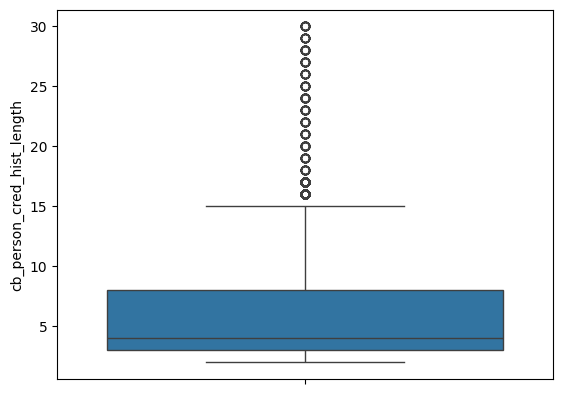

In [ ]:
sns.boxplot(data = df.cb_person_cred_hist_length)

ошибок нет

## Итого
### Обработка пропущенных значений:

loan_int_rate — заполнена медианным значением в разрезе кредитного рейтинга (loan_grade), так как процентная ставка напрямую зависит от рейтинга заёмщика

person_emp_length — заполнена медианным значением в разрезе возрастной группы (20–35, 36–60, 61–95 лет)

### Обработка выбросов:

Удалены записи с нереалистичным возрастом (> 95 лет) — 5 записей

Удалены записи с нереалистичным стажем работы (> 80 лет) — 1 запись



## Анализ целевой переменной

In [ ]:
df['loan_status'].value_counts()

,count
loan_status,
0,25467
1,7107


<Axes: xlabel='loan_status', ylabel='count'>

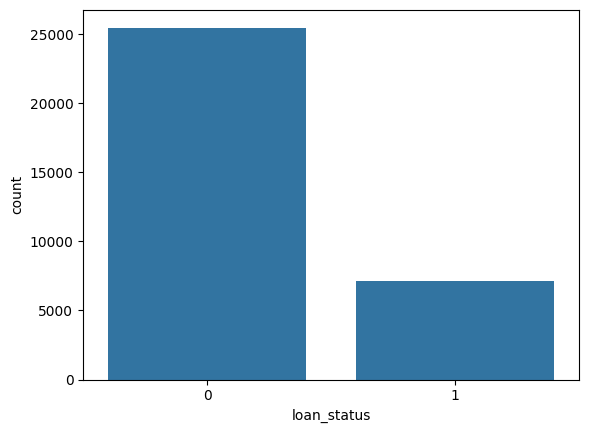

In [ ]:
sns.countplot(x = 'loan_status', data = df)

Классов целевой переменной 2 это 0 и 1. 0 означает, что кредит был вернут, а 1 - дефолт. Сильно чаще встречается класс 0. Процент дефолтов около 22. Наблюдается дисбаланс классов. Модель может быть склонна предсказывать класс 0 для всех, так как это даёт высокую accuracy. Понадобятся специальные метрики и техники балансировки.

<Axes: xlabel='loan_status', ylabel='person_age'>

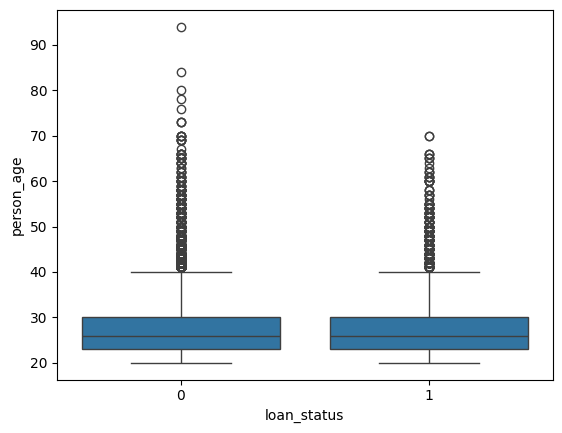

In [ ]:
sns.boxplot(data=df, x=df['loan_status'], y=df['person_age'])

 Возраст слабо разделяет классы — распределения почти одинаковые. Значит этот признак вряд ли будет очень важным для модели.

<Axes: xlabel='loan_status', ylabel='person_income'>

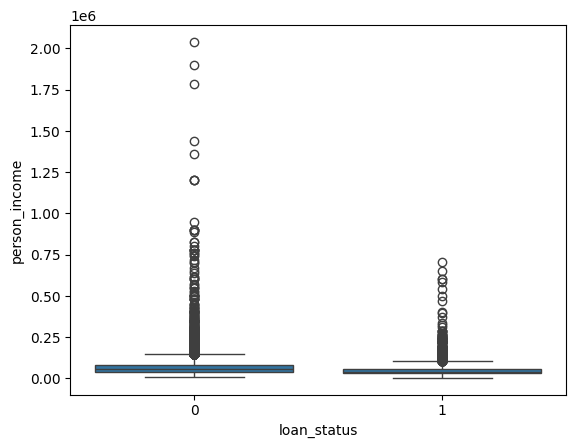

In [ ]:
sns.boxplot(data=df, x=df['loan_status'], y=df['person_income'])

в person_income есть выбросы, но важнее уровень и размер ящиков он одинаковый практически, значит этот признак будет не очень важным

In [ ]:
df.head(3)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2


<Axes: xlabel='loan_status', ylabel='person_emp_length'>

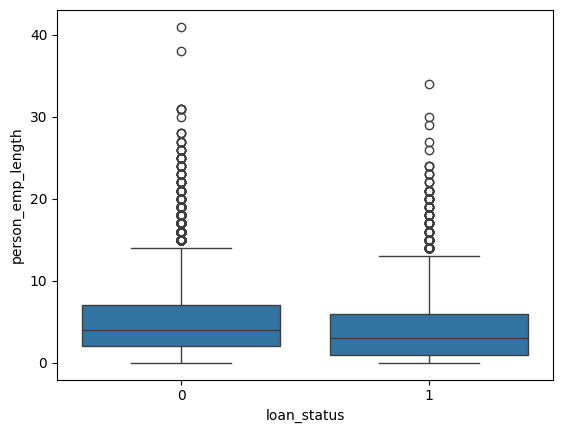

In [ ]:
sns.boxplot(data=df, x=df['loan_status'], y=df['person_emp_length'])

person_emp_length немного различаются, чем меньше продолжительность кредитной истории, тем чаще происходит дефолт

<Axes: xlabel='loan_status', ylabel='cb_person_cred_hist_length'>

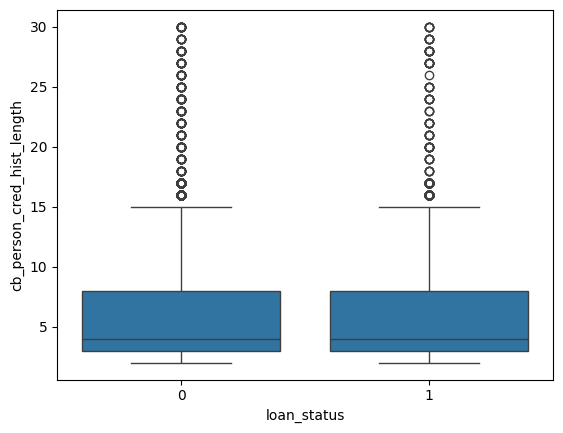

In [ ]:
sns.boxplot(data=df, x=df['loan_status'], y=df['cb_person_cred_hist_length'])

cb_person_cred_hist_length такой же нет смысла рассматривать

<Axes: xlabel='loan_status', ylabel='loan_amnt'>

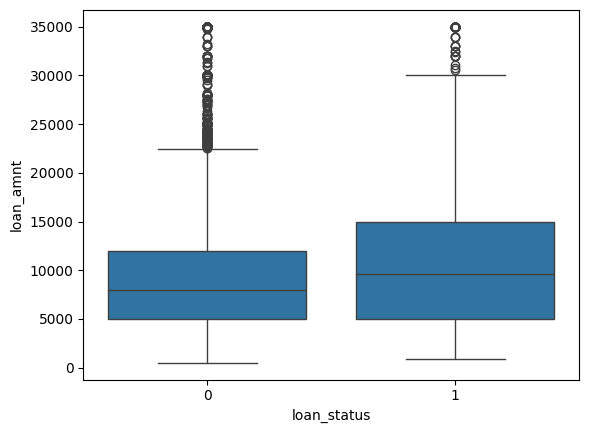

In [ ]:
sns.boxplot(data=df, x=df['loan_status'], y=df['loan_amnt'])

в loan_amnt чем больльше сумма кредита, тем больше шанс дефолта

<Axes: xlabel='loan_status', ylabel='loan_int_rate'>

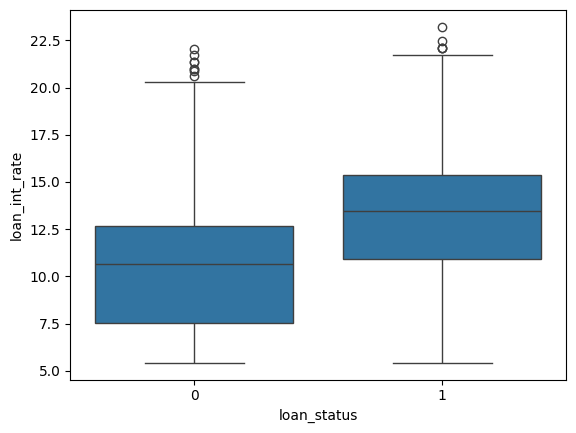

In [ ]:
sns.boxplot(data=df, x=df['loan_status'], y=df['loan_int_rate'])

в loan_int_rate чем больше процентная ставка, тем чаще происходит дефолт

<Axes: xlabel='loan_status', ylabel='loan_percent_income'>

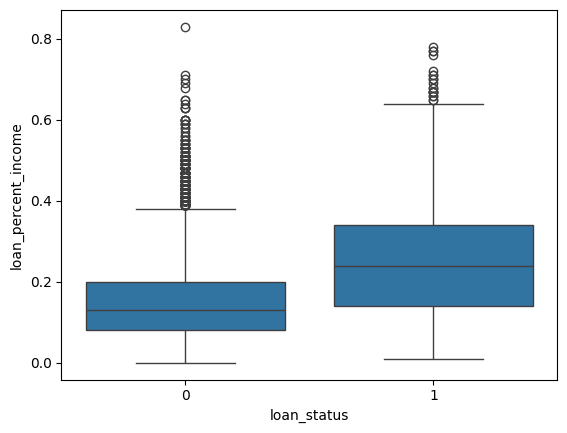

In [ ]:
sns.boxplot(data=df, x=df['loan_status'], y=df['loan_percent_income'])

в loan_percent_income чем выше процент, тем чаще дефолт

<Axes: xlabel='loan_grade', ylabel='count'>

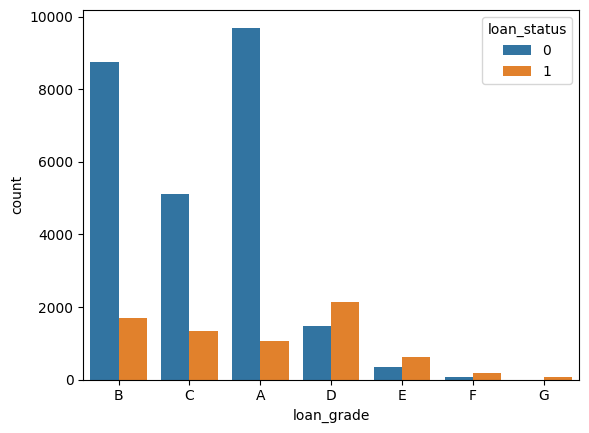

In [ ]:
sns.countplot(data = df, x = 'loan_grade', hue = 'loan_status' )

Рейтинг по кредитам клиентов тесно связан с их возвратами, поэтому у клиентов с категорией A не очень много дефолтов, и возвратов сильно больше, в категориях В и С аналогичная ситуация, но в каждом из них дефолтов чуть больше соответственно; в D невозвратов больше, чем возвратов, что крайне важно, в E и F аналогичная ситуация, но в целом выдаваемых кредитов меньше, G практически кредиты не выдают, а тем кому дают, они не возвращают. Итого чем хуже рейтинг, тем вероятнее дефолт

<Axes: xlabel='loan_intent', ylabel='count'>

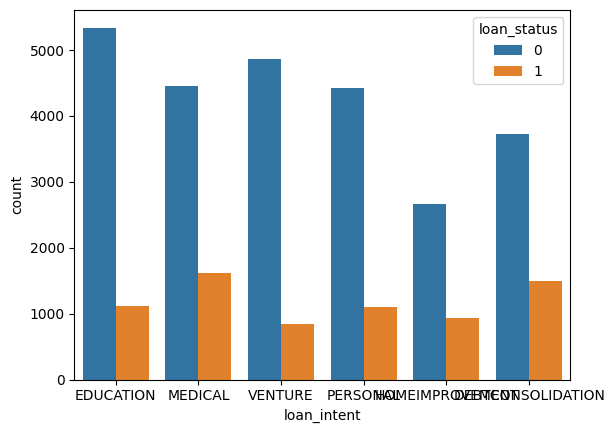

In [ ]:
sns.countplot(data = df, x = 'loan_intent', hue = 'loan_status' )

наиболее частый дефолт происходит когда люди берут medical, это может быть связано с тем, что они долго восстанавливаются и не могут работать соответсвенно и выплачивать кредит. Так же стоит обратить внимание, что по соотношению с выплаченными наибольший процент у debtconsolidation это может быть по причине что человек уже накопил много долгов и пытается их объединить в один. Итого: цель кредита влияет на дефолт

<Axes: xlabel='person_home_ownership', ylabel='count'>

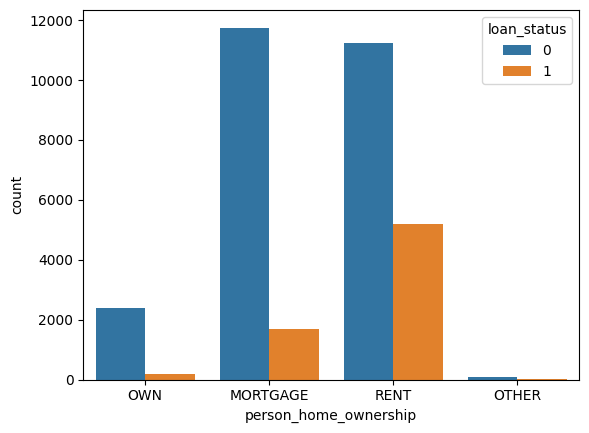

In [ ]:
sns.countplot(data = df, x = 'person_home_ownership',  hue = 'loan_status' )

видно, что чаще те кто арендуют не возвращают кредит, это может быть связано с тем, кто арендует жилье еще платит за него большую сумму из-за чего на выплату кредита не остается или же владелец жилья или человек с ипотекой уже доказал свою платёжеспособность. А арендатор может быть менее финансово стабильным

<Axes: xlabel='cb_person_default_on_file', ylabel='count'>

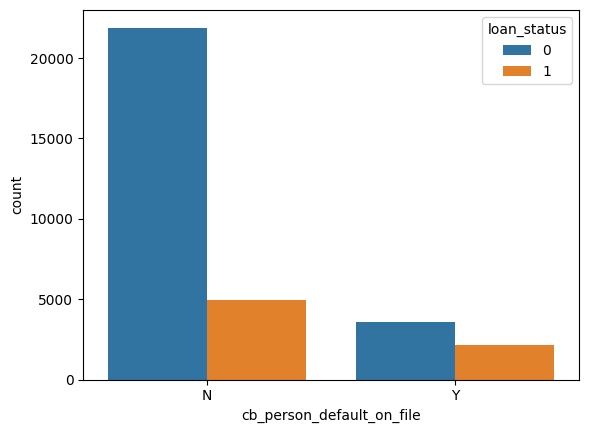

In [ ]:
sns.countplot(data = df, x = 'cb_person_default_on_file',  hue = 'loan_status' )

те кто имел дефолт сильно меньше возвращают его, да и выдают таким клиентам кредит сильно реже

## Итого, наиболее важные категории для модели:
1. рейтинг (loan_grade)
2. процент кредита (loan_percent_income)
3. процентная ставка (loan_int_rate)
4. был ли дефолт (cb_person_default_on_file)

In [ ]:
df.head(2)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3


In [ ]:
X = df[['person_age','person_income','person_emp_length','loan_amnt',"loan_int_rate", "loan_percent_income", 'cb_person_cred_hist_length', 'person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']]
y = df[["loan_status"]]

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify = y)

In [ ]:
X_train.shape, X_test.shape

((24430, 11), (8144, 11))

In [ ]:
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
categorical = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
numeric_features = ['person_age','person_income','person_emp_length','loan_amnt',"loan_int_rate",'loan_percent_income']

In [ ]:
ct = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown="ignore"), categorical),
    ('scaling', MinMaxScaler(), numeric_features)
])
X_train_transformed = ct.fit_transform(X_train)
X_test_transformed = ct.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(class_weight='balanced')

In [ ]:
model.fit(X_train_transformed, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:1352: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [ ]:
from sklearn.metrics import accuracy_score
pred = model.predict(X_test_transformed)
accuracy_score(y_test, pred)

0.8075884086444007

In [ ]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, pred)

array([[5239, 1128],
       [ 439, 1338]])

действительно 0 - 5239, а было предсказано 1 - 1128

действительно 1 - 1338, а было предсказано 0 - 439

чаще ошибалась модель в том, когда нужно было сказать 0

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       0.92      0.82      0.87      6367
           1       0.54      0.75      0.63      1777

    accuracy                           0.81      8144
   macro avg       0.73      0.79      0.75      8144
weighted avg       0.84      0.81      0.82      8144



Базовая модель: логистическая регрессия с class_weight='balanced'. recall = 0.75 — модель находит 75% реальных дефолтов
precision = 0.54 — из всех кого модель назвала дефолтом, только 54% реально дефолт
это плохо тем что она называет слишком много дефолтов и может отказывать хорошим клиентам. F1-score для класса дефолт составил 0.63 — это наш baseline, с которым будем сравнивать следующие модели.

попробуем иначе обучить модель

In [ ]:
from sklearn.ensemble import RandomForestClassifier
model_rf = RandomForestClassifier(class_weight='balanced')

In [ ]:
model_rf.fit(X_train_transformed, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [ ]:
from sklearn.metrics import accuracy_score
pred_rf = model_rf.predict(X_test_transformed)
accuracy_score(y_test, pred)

0.8075884086444007

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, pred_rf))

              precision    recall  f1-score   support

           0       0.92      0.99      0.96      6367
           1       0.97      0.70      0.82      1777

    accuracy                           0.93      8144
   macro avg       0.95      0.85      0.89      8144
weighted avg       0.93      0.93      0.93      8144



Сравнив две модели можно увидеть, что Random Forest пропускает больше дефолтов так как тут recall =  0.70, а у логической регрессии recall = 0.75, но зато когда говорит "дефолт" — почти всегда прав тут precision 0.97, а в логической регрессии precision = 0.54. Но F1 у Random Forest выше (0.82 vs 0.63) — значит в целом он лучше. Для банка скорее подойдет Random Forest

In [ ]:
from sklearn.model_selection import GridSearchCV

model_rf =  RandomForestClassifier(class_weight='balanced')

params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 20, None]
}

gs = GridSearchCV(model_rf, params, scoring='f1', cv=3, n_jobs=-1, verbose=2)
gs.fit(X_train_transformed, y_train)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ht='balanced')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [5, 10, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 

In [ ]:
gs.best_score_

np.float64(0.8234952350196538)

In [ ]:
from sklearn.metrics import accuracy_score
pred_rf = gs.best_estimator_.predict(X_test_transformed)
accuracy_score(y_test, pred_rf)

0.931114931237721

In [ ]:
print(classification_report(y_test, pred_rf))

              precision    recall  f1-score   support

           0       0.92      0.99      0.96      6367
           1       0.97      0.70      0.82      1777

    accuracy                           0.93      8144
   macro avg       0.95      0.85      0.89      8144
weighted avg       0.93      0.93      0.93      8144



GridSearchCV нашёл лучшие параметры, но улучшения незначительные, но оставим ее как лучшую

In [ ]:
import joblib
joblib.dump(gs.best_estimator_, 'model.pkl')
joblib.dump(ct, 'transformer.pkl')

['transformer.pkl']

In [ ]:
loaded_model = joblib.load('model.pkl')
pred_loaded = loaded_model.predict(X_test_transformed)
(pred_loaded == pred_rf).all()

np.True_